# Modèle APT – mode synchrone (Fig. 7a)

**Article :** Cosme, Thomas & Gaucherel (2023), *On the History of Ecosystem Dynamical Modeling: The Rise and Promises of Qualitative Models*, Entropy 25(11), 1526.

## Objectif
Reproduire la Fig. 7a : le même modèle APT que dans `APT_asynchrone (1).ipynb`, mais exécuté en **mode synchrone**, où toutes les règles applicables sont tirées **simultanément** à chaque pas. C'est le mode de la plupart des modèles dynamiques (section 3.2), que l'article met en défaut.

## Rappel du modèle
Règles de l'asynchrone (Fig. 5b) : R1 `A+ >> P-`, R2 `A+ >> T-`, R3 `P+ >> T-`, R4 `P- >> A-`.

## Comment on exprime le synchrone dans `ecco`
`ecco` exécute les règles une par une, mais une règle peut modifier **plusieurs variables à la fois**. On simule donc le synchrone en **regroupant en une seule règle** les règles qui doivent être tirées ensemble. `APT_synchrone.rr` contient :

| Règle | Écriture | Ce qu'elle regroupe |
|---|---|---|
| S1 | `A+, P+, T+ >> P-, T-` | R1, R2 et R3 tirées ensemble depuis {APT} |
| S2 | `A+, P-, T- >> A-` | R4 depuis {A} (P est absent, A s'éteint) |

Dans la Fig. 7a, on a donc : {APT} →(R1, R2 et R3) {A} →(R4) {∅}.

## 1. Chargement de la bibliothèque

In [1]:
import ecco
print("ECCO est disponible")

ECCO est disponible


## 2. Chargement du modèle synchrone

In [2]:
rr_sync, model_sync = ecco.load("APT_synchrone.rr")

## 3. Calcul et affichage du graphe d'états
Même procédure qu'en asynchrone : `model_sync()` calcule tous les états atteignables depuis {APT}, `explicit()` les sépare en un nœud par état, `draw()` affiche le STG.

In [3]:
graph_sync = model_sync().explicit()
graph_sync.draw()

## 4. Résultat attendu (Fig. 7a) et vérification

Le graphe doit être **une simple chaîne de 3 états** :

**{APT} → {A} → {∅}**

- [x] 3 états seulement : APT, A, ∅ ;
- [x] aucune ramification : une **seule trajectoire**, donc un modèle déterministe ;
- [x] un seul état stable : **{∅}** ;
- [x] l'état **{T} n'apparaît pas**.

**Lecture du graphe obtenu dans ecco** (capture `figures/ecco_synchrone.png`) : 3 ▶ = APT (état initial) → 2 = A (règle S1) → 1 ■ = ∅ (règle S2, état stable).

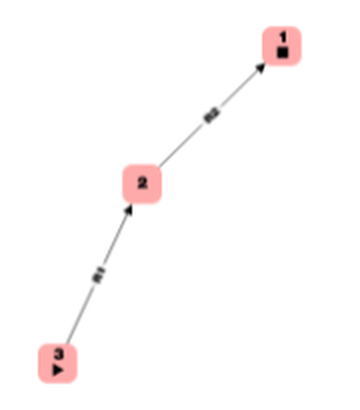

*Capture de la sortie de `draw()` ci-dessus, jointe ici car le widget interactif ne s'affiche pas quand le notebook est ouvert en dehors de Jupyter.*

## 5. Interprétation

- En synchrone, R1, R2 et R3 sont tirées en même temps depuis {APT} : P et T disparaissent ensemble, il reste {A}, puis A s'éteint à son tour. La dynamique est **déterministe** et finit toujours en {∅}.
- Or l'état {T} est **observé expérimentalement** (Weatherby et al., 1998). Le modèle synchrone ne le prédit pas : soit la structure des interactions est fausse, soit la façon dont les événements sont ordonnancés est inappropriée. Comme le modèle asynchrone, à structure d'interactions identique, retrouve {T}, c'est **l'hypothèse de synchronisme** qui est en cause.
- Le synchrone suppose implicitement que tous les processus ont la même vitesse, comme si une horloge globale les cadençait. C'est une hypothèse forte en écologie, et elle peut conduire à **rejeter à tort** un modèle correct (faux négatifs).

## 6. Limites de cette reproduction
- Le synchrone est ici codé **à la main**, avec deux règles regroupées qui ne valent que pour la trajectoire partant de {APT}. Ce n'est pas un vrai mode synchrone générique : depuis un autre état, par exemple {AT}, ces règles ne s'appliqueraient pas comme le ferait un tir simultané de R1 à R4 : un vrai pas synchrone ferait passer {AT} à {∅} (R2 et R4 ensemble), alors qu'aucune règle de `APT_synchrone.rr` ne s'y applique.
- Cela suffit pour reproduire la Fig. 7a, mais pas pour conclure que le synchrone échoue pour tout modèle. L'article le nuance lui-même, en notant que certains modèles booléens synchrones donnent de bons résultats en écologie, et en adoptant un mode *partiellement synchrone* pour plus de souplesse.